# 6 · Correlated noise

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → **6 · Correlated noise** → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb)

**Question.** So far each channel qubit was disturbed on its own. In a real link the two channels can talk to each
other: crosstalk. What can a *local* correction (one gate per qubit, as in notebooks 3–5) still achieve, and what
does a *two-qubit* correction add?

**The channel** (nominal, on q2, q3, in this order): the rotations N1; crosstalk exp(−i/2 [ζ ZZ + ε (XX + YY)/2])
with ZZ coupling ζ = 0.6 and exchange ε = 0.3; correlated dephasing (ZZ with probability 0.05); and the device-like
incoherent noise M with p = 0.05 (notebook 5). Below, *crosstalk strength* x scales ζ and ε together.

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import numpy as np
import matplotlib.pyplot as plt
from telecorr import correlated as X, detector, tomography as tomo
from telecorr.paulis import KEYS4
from telecorr.rotations import u_matrix
from telecorr.states import MESSAGES, message_state
from telecorr.reference import simulation, path, number
from telecorr.plotting import use_style, CONDITION, INK_2
from telecorr.report import md_table, show
use_style()
MSG = [message_state(n) for n in MESSAGES]
T = X.T15()                                   # the nominal channel's 15 x 15 transfer matrix

## The model: a two-qubit twirl

Teleportation twirls any channel on (q2, q3) into a **two-qubit Pauli channel** (Theorem T6.2). With the 15 × 15
transfer matrix T of the channel and a correction W with adjoint matrix Ad(W), Bob's Pauli eigenvalues are the
diagonal of Ad(W) T and (Theorem T6.3)

$$p_{II} = \frac{1 + \operatorname{tr}(\mathrm{Ad}(W)\,T)}{16}, \qquad F_\text{avg} = \frac{4\, p_{II} + 1}{5}.$$

* A **local** correction W = V₂ ⊗ V₃ sees the correlated block of T only through a coupling term. TOMO-9 on each
  leg (notebook 7) ignores it and converges to the per-leg Procrustes rotations; alternating Procrustes finds the
  best local correction.
* A **two-qubit** correction can undo the crosstalk unitary. Its best value is certified by an upper bound (the
  largest eigenvalue of the process matrix χ), and Newton steps on SU(4) reach it. When the incoherent part is
  symmetric positive semidefinite, the inverse of the unitary part is optimal (Theorem T6.5). For non-unital noise
  this is not guaranteed in general; for the channels of this study it is certified numerically.
* Pure ZZ crosstalk by an angle φ shows the limit sharply: the best local correction reaches only
  p_II = max(cos², sin²)(φ/2), while the two-qubit correction reaches 1 (Theorem T6.7).

In [2]:
rows = []
for phi in (0.3, 0.8, 1.5, 2.2, 3.0):
    Tz = X.ptm15([X.crosstalk_unitary(phi, 0.0)])
    rows.append((phi, X.zz_local_ceiling(phi), (1 + np.trace(X.adj(X.best_local(Tz)) @ Tz)) / 16,
                 (1 + np.trace(X.adj(X.best_su4(Tz)) @ Tz)) / 16))
show(md_table(rows, ["ZZ angle φ (rad)", "formula max(cos², sin²)(φ/2)", "best local p_II (computed)", "best two-qubit p_II"], 4))

| ZZ angle φ (rad) | formula max(cos², sin²)(φ/2) | best local p_II (computed) | best two-qubit p_II |
|---|---|---|---|
| 0.3000 | 0.9777 | 0.9777 | 1.0000 |
| 0.8000 | 0.8484 | 0.8484 | 1.0000 |
| 1.5000 | 0.5354 | 0.5354 | 1.0000 |
| 2.2000 | 0.7943 | 0.7943 | 1.0000 |
| 3.0000 | 0.9950 | 0.9950 | 1.0000 |

## Result: what each correction can reach

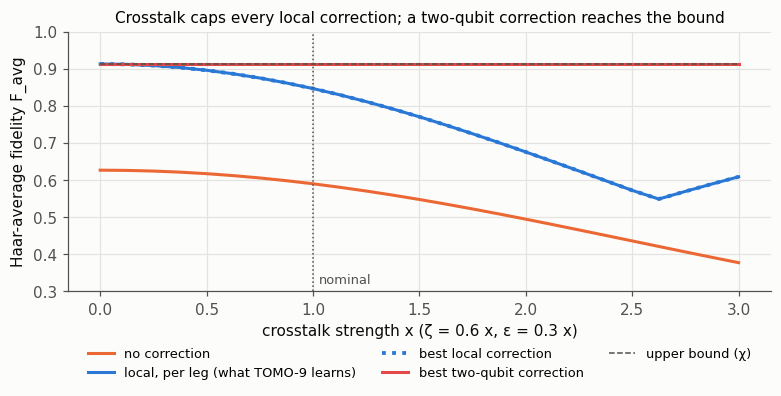

In [3]:
xs = np.linspace(0, 3, 25)
curves = {k: [] for k in ("none", "per-leg", "local", "two-qubit", "bound")}
for x in xs:
    Tx = X.T15(xt=x)
    W = X.ceilings(Tx)
    for k, key in (("none", "no correction"), ("per-leg", "per-leg Procrustes (TOMO-9)"), ("local", "best local"), ("two-qubit", "best two-qubit")):
        curves[k].append(X.favg(W[key], Tx))
    curves["bound"].append(X.favg_bound(Tx))
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(xs, curves["none"], color=CONDITION["no correction"], label="no correction")
ax.plot(xs, curves["per-leg"], color=CONDITION["learned from counts"], label="local, per leg (what TOMO-9 learns)")
ax.plot(xs, curves["local"], color=CONDITION["learned from counts"], ls=":", lw=2.5, label="best local correction")
ax.plot(xs, curves["two-qubit"], color=CONDITION["two-qubit correction"], label="best two-qubit correction")
ax.plot(xs, curves["bound"], color=INK_2, ls="--", lw=1, label="upper bound (χ)")
ax.axvline(1, color=INK_2, lw=1, ls=":"); ax.text(1.03, 0.32, "nominal", color=INK_2, fontsize=8.5)
ax.set_xlabel("crosstalk strength x (ζ = 0.6 x, ε = 0.3 x)"); ax.set_ylabel("Haar-average fidelity F_avg"); ax.set_ylim(0.3, 1.0)
ax.set_title("Crosstalk caps every local correction; a two-qubit correction reaches the bound", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8.5); plt.tight_layout(); plt.show()

In [4]:
saved = {r["label"]: r for r in simulation("6a_nominal.json")["rows"]}
W = X.ceilings(T)
names = {"no correction": "no correction", "per-leg Procrustes (TOMO-9)": "per-leg Procrustes (= TOMO-9 on each leg)",
         "best local": "best local (6 parameters)", "best two-qubit": "best two-qubit (15)"}
rows = [(k, X.favg(Wk, T), X.fidelity(MSG[0], Wk, T), X.fidelity(MSG[1], Wk, T), saved[names[k]]["favg"]) for k, Wk in W.items()]
rows.append(("upper bound (χ)", X.favg_bound(T), None, None, simulation("6a_nominal.json")["bound"]))
show(md_table(rows, ["correction (nominal channel)", "F_avg", "F product_HT", "F bell_30_70", "F_avg, the study's table"], 6))

| correction (nominal channel) | F_avg | F product_HT | F bell_30_70 | F_avg, the study's table |
|---|---|---|---|---|
| no correction | 0.590199 | 0.657656 | 0.578445 | 0.590199 |
| per-leg Procrustes (TOMO-9) | 0.846817 | 0.834050 | 0.829068 | 0.846817 |
| best local | 0.846824 | 0.834054 | 0.829090 | 0.846824 |
| best two-qubit | 0.913123 | 0.911239 | 0.907264 | 0.913123 |
| upper bound (χ) | 0.913176 | - | - | 0.913176 |

## Learning the two-qubit correction: TOMO-75

A probe circuit with a two-qubit Clifford setting in the correction box and a stabilizer probe state reads exactly
three entries of M = Ad(W) T. A design of **75 circuits** (45 with product probes, 30 with entangled probes) reads
each of the 225 entries exactly once. That is the minimum (225 / 3), and probe states without entanglement would
need at least 135 circuits (Theorem T6.11). The design of the study is loaded and checked, then used from counts:

In [5]:
design = X.load_tomo75(path("6a_tomo75_design.json"))
A = X.design_matrix(design)
groups = X.probe_groups()
show(f"{len(design)} circuits ({sum(groups[g]['product'] for _, g in design)} product probes, "
     f"{sum(not groups[g]['product'] for _, g in design)} entangled); design matrix AᵀA = I: {np.allclose(A.T @ A, np.eye(225))}.")
rng = np.random.default_rng(61)
Fceil = X.favg(W["best two-qubit"], T)
Fleg = X.favg(W["per-leg Procrustes (TOMO-9)"], T)
rows = []
for N in (1000, 10000):
    g75, g9 = [], []
    for _ in range(10):
        V = X.best_su4(X.estimate_M(design, X.sample_lambdas(rng, design, T, N)))
        g75.append(Fceil - X.favg(V, T))
        counts = [dict(zip(KEYS4, rng.multinomial(N, p / p.sum()))) for p in X.tomo9_probs(T)]
        x9 = tomo.estimate(counts, "tomo9")["x_new"]
        W9 = np.kron(u_matrix(*x9[3:]), u_matrix(*x9[:3]))
        g9.append(Fleg - X.favg(W9, T))
    rows.append((N, "TOMO-9 (local)", 9 * N, Fleg, np.mean(g9)))
    rows.append((N, "TOMO-75 (two-qubit)", 75 * N, Fceil, np.mean(g75)))
show(md_table([(n, m, s, f"{c:.5f}", f"{g:.1e}") for n, m, s, c, g in rows],
              ["shots per circuit", "method", "total shots", "its ceiling (F_avg)", "mean gap to that ceiling (10 runs)"]))
show(f"The study's runs, per message: local TOMO-9 {number('n0028')} / {number('n0032')}, TOMO-75 {number('n0029')} / {number('n0033')} "
     "(product_HT / bell_30_70).")

75 circuits (45 product probes, 30 entangled); design matrix AᵀA = I: True.

| shots per circuit | method | total shots | its ceiling (F_avg) | mean gap to that ceiling (10 runs) |
|---|---|---|---|---|
| 1000 | TOMO-9 (local) | 9000 | 0.84682 | 9.3e-04 |
| 1000 | TOMO-75 (two-qubit) | 75000 | 0.91312 | 4.8e-04 |
| 10000 | TOMO-9 (local) | 90000 | 0.84682 | 1.0e-04 |
| 10000 | TOMO-75 (two-qubit) | 750000 | 0.91312 | 4.6e-05 |

The study's runs, per message: local TOMO-9 0.8338 / 0.8288, TOMO-75 0.9112 / 0.9072 (product_HT / bell_30_70).

## Detecting crosstalk for free

A local channel keeps Bob's two bits independent in every TOMO-9 circuit. Correlation between them is therefore a
signature of crosstalk that costs no extra shots: the detector is a Pearson χ² test of independence over the nine
TOMO-9 count tables (`telecorr.detector`). Its false-alarm rate on a product channel, and its verdict on the nominal
channel:

In [6]:
product = X.T15(dict(X.NOMINAL6, zz=0.0, ex=0.0, pc=0.0))
rng = np.random.default_rng(51)
def run(Tm, N):
    c = [dict(zip(KEYS4, rng.multinomial(N, p / p.sum()))) for p in X.tomo9_probs(Tm)]
    return detector.detect(c, N)["p"]
fa = {N: np.mean([run(product, N) < 1e-3 for _ in range(4000)]) for N in (1000, 3000)}
saved = simulation("6b_detector_counts.json")["false_alarm"]
rows = [(N, 1e-3, fa[N], saved[str(N)]["rate"]) for N in (1000, 3000)]
show(md_table(rows, ["shots per circuit", "nominal level α", "false-alarm rate (4000 product channels)", "the study's rate (20 000)"], 4))
show("On the nominal channel with 1000 shots per circuit the detector returns p = " +
     ", ".join(f"{run(T, 1000):.1e}" for _ in range(3)) + " in three independent runs.")

| shots per circuit | nominal level α | false-alarm rate (4000 product channels) | the study's rate (20 000) |
|---|---|---|---|
| 1000 | 0.0010 | 0.0008 | 0.0008 |
| 3000 | 0.0010 | 0.0008 | 0.0013 |

On the nominal channel with 1000 shots per circuit the detector returns p = 2.1e-76, 3.4e-66, 1.5e-87 in three independent runs.

## What it means

* Crosstalk sets a hard limit on any local correction: at the nominal strength the best local correction stops at
  F_avg ≈ 0.85, and TOMO-9 learns essentially that optimum.
* A two-qubit correction removes the crosstalk unitary and reaches the certified bound (F_avg ≈ 0.91; what is left is
  incoherent). TOMO-75 learns it from counts with the minimal number of circuits, at about eight times TOMO-9's
  cost in circuits.
* Correlation between Bob's bits in the ordinary TOMO-9 data flags crosstalk at no extra cost, with the false-alarm
  rate it promises.

**Next (notebook 7):** every calibrator so far spends millions of shots. What is the most shot-efficient way to
learn the correction, and to keep it right while the channel drifts?